# PetFinder – 2. mérföldkő: adat-előkészítés és jellemzőelemzés

A feladat célja
A PetFinder Adoption Prediction adatkészlet örökbefogadásra váró állatokról szóló hirdetéseket tartalmaz. Egy-egy sorhoz többek között az állat életkora, fajtája, egészségi adatai, a hirdetés szövege és fényképei kapcsolódnak. A megjósolandó változó az AdoptionSpeed, amely 0 és 4 közötti, sorrenddel rendelkező kategóriákkal jellemzi az örökbefogadás gyorsaságát.

Ennek a mérföldkőnek a célja az adatok előkészítése és a hasznos jellemzők feltárása. Ennek részeként megvizsgáljuk és javítjuk az adatminőséget, elkülönítjük a tanító-, validációs és tesztadatokat, átalakítjuk a meglévő változókat, új jellemzőket hozunk létre, majd elemezzük és kiválasztjuk őket. A létrehozott jellemzők hasznosságát egyszerű gépi tanulási modellek összehasonlításával is ellenőrizzük.

A notebook minden szakaszában bemutatjuk az alkalmazott lépés célját, működését és indoklását, valamint értelmezzük a kapott eredményeket.


## 1. Adatok letöltése és betöltése

### Mit csinálunk?

Beolvassuk a PetFinder hivatalos `train/train.csv` és `test/test.csv` fájlját. A **train** tartalmazza a megtanulandó `AdoptionSpeed` címkét, a hivatalos **test** viszont nem. Ezért a későbbi objektív kiértékeléshez a címkézett adatokból is elkülönítünk egy **belső teszthalmazt** (3. rész).

### Hogyan működik?

- Betöltjük a szükséges Python-könyvtárakat, és a `SEED = 42` véletlenszám-kezdőértékkel biztosítjuk, hogy a véletlen lépések ugyanazzal a beállítással megismételhetők legyenek.
- A Google Colabban az adatok a `/content` mappába kerülnek. Ha hiányzik a Kaggle API-kulcs, a cella bekéri a `kaggle.json` fájlt.
- A `kaggle competitions download` **egyszer tölti le a teljes** `petfinder-adoption-prediction.zip` versenyarchívumot. A CSV-ket ebből másoljuk ki, a fényképeket pedig a 7. részben közvetlenül a ZIP-ből olvassuk. Nem bontunk ki több tízezer képet külön fájlba.
- A `PetID` egyedisége és a célváltozó jelenléte/hiánya `assert` utasításokkal ellenőrzött. Ha az elvárás nem teljesül, a futás hibával megáll – így nem készül észrevétlenül hibás elemzés.

### Miért jó ez?

A fájlok gyorsítótárazásával nem töltünk le mindent újra; az ellenőrzések pedig segítenek felismerni a rossz vagy hiányos adatforrást. A `PetID` később **nem** lesz modellbemenet: csak az egyes hirdetések azonosítására szolgál.

**Tényleges kimenet:** 14 993 címkézett hirdetés, 24 oszlop; 3 972 címkézetlen Kaggle-teszt hirdetés, 23 oszlop. A különbség pontosan az `AdoptionSpeed` céloszlop.


In [ ]:
# Alapkönyvtárak: programindítás, ZIP-olvasás, véletlen számok, szöveg és fájlműveletek.
import sys, subprocess, zipfile, random, re, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb

# A rögzített seed a felosztást és a véletlen mintaválasztásokat ismételhetővé teszi.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    from google.colab import files
    ROOT = Path("/content")
except ImportError:
    files = None
    ROOT = Path.cwd()

# Minden ábra, táblázat, modell és predikció egy külön eredménymappába kerül.
OUT = ROOT / "petfinder_m2_results"
OUT.mkdir(exist_ok=True)

train_path = ROOT / "train" / "train.csv"
test_path = ROOT / "test" / "test.csv"


# A függvény mindig ugyanazt a teljes ZIP-et adja vissza; a filename régebbi hívásokhoz maradt.
def kaggle_download(filename=None):
    """Egyszer letölti a teljes Kaggle-versenyarchívumot."""
    archive = ROOT / "petfinder-adoption-prediction.zip"

    if archive.exists():
        return archive

    token = Path.home() / ".kaggle" / "kaggle.json"

    if not token.exists():
        assert files is not None, "A kaggle.json API-kulcs szükséges."

        print("Töltsd fel a kaggle.json fájlt:")
        uploaded = files.upload()
        assert "kaggle.json" in uploaded

        token.parent.mkdir(parents=True, exist_ok=True)
        token.write_bytes(uploaded["kaggle.json"])
        token.chmod(0o600)

    if shutil.which("kaggle") is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "kaggle"
        ])

    print("A PetFinder-adatbázis letöltése a Kaggle-ről...")

    subprocess.run([
        "kaggle", "competitions", "download",
        "-c", "petfinder-adoption-prediction",
        "-p", str(ROOT)
    ], check=True)

    assert archive.exists(), "A Kaggle-archívum letöltése sikertelen."
    return archive


# CSV-fájlok kinyerése a letöltött archívumból
# CSV-ket csak szükség esetén másolunk ki a ZIP-ből; a képek a ZIP-ben maradnak.
if not train_path.exists() or not test_path.exists():

    archive = kaggle_download()

    with zipfile.ZipFile(archive) as z:

        for split, csv_path in (
            ("train", train_path),
            ("test", test_path)
        ):
            if not csv_path.exists():

                filename = f"{split}/{split}.csv"

                if filename not in z.namelist():
                    raise FileNotFoundError(
                        f"Hiányzik az archívumból: {filename}"
                    )

                csv_path.parent.mkdir(parents=True, exist_ok=True)

                with z.open(filename) as source:
                    with csv_path.open("wb") as destination:
                        shutil.copyfileobj(source, destination)


# Adatok beolvasása és ellenőrzése
raw_train = pd.read_csv(train_path)
raw_test = pd.read_csv(test_path)

# Gyors adatellenőrzések: train címkézett, Kaggle-test címkézetlen, egy sor = egy PetID.
assert "AdoptionSpeed" in raw_train.columns
assert "AdoptionSpeed" not in raw_test.columns
assert raw_train.PetID.is_unique
assert raw_test.PetID.is_unique

print("Train:", raw_train.shape)
print("Kaggle test:", raw_test.shape)

display(raw_train.head(3))

Töltsd fel a kaggle.json fájlt:


Saving kaggle.json to kaggle.json
A PetFinder-adatbázis letöltése a Kaggle-ről...
Train: (14993, 24)
Kaggle test: (3972, 23)


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Nibble,3,299,0,1,1,7,0,1,...,1,1,100,41326,8480853f516546f6cf33aa88cd76c379,0,Nibble is a 3+ month old ball of cuteness. He ...,86e1089a3,1.0,2
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,1,1,0,41401,3082c7125d8fb66f7dd4bff4192c8b14,0,I just found it alone yesterday near my apartm...,6296e909a,2.0,0
2,1,Brisco,1,307,0,1,2,7,0,2,...,1,1,0,41326,fa90fa5b1ee11c86938398b60abc32cb,0,Their pregnant mother was dumped by her irresp...,3422e4906,7.0,3


## 2. Adatminőség ellenőrzése és javítása

### Mit vizsgálunk?

Az előző mérföldkő adatfeltárásában megfigyelt problémákra **ellenőrizhető, egyszerű szabályokat** írunk. A `audit()` megszámolja a hibákat, a `clean()` pedig kijavítja őket. Ugyanazt a tisztító függvényt futtatjuk a címkézett és a címkézetlen adatokon is.

| Probléma | Javítás | Miért? |
|---|---|---|
| Hiányzó vagy `No Name Yet` típusú név | Egységes `NA` hiányzó érték | Az ilyen szöveg nem valódi állatnév. |
| Hiányzó `Description` | Üres karakterlánc `""` | A szöveges feldolgozó így minden soron biztonságosan fut. |
| `Breed1 = 0`, miközben `Breed2 > 0` | A második fajta átkerül az első helyre | A hiányzó elsődleges kód helyére ismert kódot teszünk. |
| `Breed1 == Breed2 > 0` | A második fajta 0 lesz | Kétszer ugyanaz a fajtakód nem jelent két külön fajtát. |
| `Color2 = 0`, `Color3 > 0` | A színkód előrébb kerül | Eltüntetjük a színkódok közötti rést. |

### Mit nem változtatunk meg, és miért?

- **Nem törlünk sorokat:** a szokatlanul magas `Age` vagy `Fee` nem bizonyított adatbeviteli hiba.
- **Nem keverjük össze az orvosi kódokat:** az `1 = Yes`, `2 = No`, `3 = Not sure` külön kategória; a bizonytalanság maga is információ.
- A `Quantity > 0`, `Age >= 0`, `Fee >= 0` és az egész számként értelmezhető `PhotoAmt` **adatérvényességi ellenőrzés**. Ezek itt nem imputálások: ha valahol megsérülnek, a kód tudatosan megáll.

### Hogyan értelmezzük a tényleges kimenetet?

A címkézett adatokban **1 265 hiányzó név és 151 névhelyettesítő** volt, ezért tisztítás után **1 416 hiányzó név** látszik – ez szándékos, nem romló adatminőség. **13 hiányzó leírást** üres szöveggé alakítottunk. **5 fajtakód-felcserélést** és **1 510 ismétlődő másodlagos fajtakódot** rendeztünk. Az auditban a `Color2`-hiba **0 eset** volt, így ennél a futásnál a szabály nem változtatott sort.

**Korlát:** a névhelyettesítőket reguláris kifejezéssel keressük; ez egyszerű, jól indokolható szabály, de nem tökéletes természetesnyelv-feldolgozás. A `Name` konkrét tartalma később nem kerül a modellbe, csak azt használjuk, hogy meg van-e adva.


In [ ]:
# Olyan szövegek, amelyek névnek látszanak, de valójában 'nincs név' jelentésűek.
NAME_PATTERN = r"no name|noname|unnamed|not named|nameless|unknown"

# Az audit kizárólag SZÁMOL: megmutatja, hány problémás adat van a javítás előtt/után.
def audit(df):
    return pd.Series({
        "Hiányzó Name": df.Name.isna().sum(),
        "Névhelyettesítő": df.Name.astype("string").str.contains(NAME_PATTERN, case=False, na=False).sum(),
        "Hiányzó Description": df.Description.isna().sum(),
        "Felcserélt Breed1/Breed2": ((df.Breed1 == 0) & (df.Breed2 > 0)).sum(),
        "Ismétlődő Breed2": ((df.Breed1 == df.Breed2) & (df.Breed2 > 0)).sum(),
        "Hiányos Color2": ((df.Color2 == 0) & (df.Color3 > 0)).sum(),
    })

# A clean másolaton dolgozik: az eredeti raw_train/raw_test adatok megmaradnak.
def clean(df):
    df = df.copy()
    # Ha az első fajtakód üres, de a második ismert, előbbre helyezzük az ismert kódot.
    swap = (df.Breed1 == 0) & (df.Breed2 > 0)
    df.loc[swap, "Breed1"] = df.loc[swap, "Breed2"]
    df.loc[swap, "Breed2"] = 0
    # Két azonos fajtakód nem jelent két külön fajtát: a másodikat töröljük.
    duplicate = (df.Breed1 == df.Breed2) & (df.Breed2 > 0)
    df.loc[duplicate, "Breed2"] = 0
    gap = (df.Color2 == 0) & (df.Color3 > 0)
    df.loc[gap, "Color2"] = df.loc[gap, "Color3"]
    df.loc[gap, "Color3"] = 0
    # Szóközök levágása, üres nevek és a 'No Name' kifejezések hiányzóvá alakítása.
    name = df.Name.astype("string").str.strip().replace("", pd.NA)
    df["Name"] = name.mask(name.str.contains(NAME_PATTERN, case=False, na=False))
    df["Description"] = df.Description.fillna("")
    # A lehetetlennek tekintett értékeket ellenőrizzük; sorokat nem törlünk automatikusan.
    assert df.Quantity.gt(0).all() and df.Age.ge(0).all() and df.Fee.ge(0).all()
    assert df.PhotoAmt.notna().all() and (df.PhotoAmt == df.PhotoAmt.round()).all()
    df["PhotoAmt"] = df.PhotoAmt.astype(int)
    return df

clean_train, clean_test = clean(raw_train), clean(raw_test)
# Az 'Előtte' és 'Utána' számlálások teszik láthatóvá a beavatkozás hatását.
quality = pd.concat([audit(raw_train), audit(clean_train)], axis=1)
quality.columns = ["Előtte", "Utána"]
display(quality)
quality.to_csv(OUT / "data_quality_before_after.csv")
assert len(raw_train) == len(clean_train)


,Előtte,Utána
Hiányzó Name,1265,1416
Névhelyettesítő,151,0
Hiányzó Description,13,0
Felcserélt Breed1/Breed2,5,0
Ismétlődő Breed2,1510,0
Hiányos Color2,0,0


## 3. Train / validation / belső test szétválasztás

### Miért kell három külön adatrész?

- **Train:** ezen illesztjük a szövegfeldolgozót, a dimenziócsökkentőket és a modelleket.
- **Validation:** ezen hasonlítjuk össze a különböző jellemzőkészleteket, majd eldöntjük, melyiket választjuk.
- **Belső test:** ehhez csak **a választás után, egyszer** nyúlunk. Ez ad egy kevésbé optimista becslést arra, hogyan működik az eljárás új eseteken.

### Miért a `RescuerID` szerinti csoportos felosztás?

Egy állatmentő szervezet vagy magánszemély több hirdetést is feladhat. Az ilyen hirdetések hasonlíthatnak egymásra (hely, szövegezési stílus, gyakorlat). Ha ugyanannak a megmentőnek az állatai a tanító és a tesztrészben is szerepelnének, könnyebbé válhatna az értékelés. A **`StratifiedGroupKFold`** ezért két dolgot próbál egyszerre teljesíteni:

1. azonos `RescuerID` **soha ne kerüljön két külön halmazba**;
2. az `AdoptionSpeed` osztályarányok **lehetőleg** hasonlóak maradjanak.

Először 5 részre osztunk: egy rész a belső test; majd a fennmaradó adatokon 4 részre osztva választjuk le a validationt. A csoportok eltérő mérete miatt a végeredmény **nem pontosan 60/20/20**.

### A futás eredménye

| Részhalmaz | Hirdetés | Szerep |
|---|---:|---|
| Train | **8 751** | Illesztés |
| Validation | **3 053** | Modellválasztás |
| Belső test | **3 189** | Egyszeri ellenőrzés |

A kód három `assert` utasítással ellenőrzi, hogy a megmentőazonosítók halmazai nem metszik egymást. A felosztást `split_manifest.csv` fájlba is mentjük, így később pontosan ellenőrizhető, melyik hirdetés hova került.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# y: jósolandó osztály; groups: megmentőazonosító, amelyet nem engedünk két részbe.
y = clean_train.AdoptionSpeed.to_numpy()
groups = clean_train.RescuerID.to_numpy()
rows = np.arange(len(clean_train))

# 1. lépés: az első, 5 részre osztó csoportos felosztás egy részét tesztre tartjuk fenn.
split1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(split1.split(rows, y, groups))
# 2. lépés: a maradékból különítjük el a validationt, megmentőnként együtt tartva a sorokat.
split2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
train_rel, val_rel = next(split2.split(dev_idx, y[dev_idx], groups[dev_idx]))
train_idx, val_idx = dev_idx[train_rel], dev_idx[val_rel]

# Valódi szivárgásellenőrzés: egyetlen RescuerID sem lehet két részben.
assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(clean_train)

# A felosztás mentése segít reprodukálni és utólag auditálni a kísérletet.
splits = pd.Series("", index=clean_train.index)
splits.iloc[train_idx] = "train"
splits.iloc[val_idx] = "validation"
splits.iloc[test_idx] = "test"
display(pd.crosstab(splits, clean_train.AdoptionSpeed, margins=True))
pd.DataFrame({"PetID": clean_train.PetID, "RescuerID": groups,
              "split": splits}).to_csv(OUT / "split_manifest.csv", index=False)


AdoptionSpeed,0,1,2,3,4,All
row_0,,,,,,
test,91,612,856,747,883,3189
train,246,1816,2417,1912,2360,8751
validation,73,662,764,600,954,3053
All,410,3090,4037,3259,4197,14993


## 4. A jellemzők előzetes feltáró elemzése (EDA)

### Mit ábrázolunk?

1. **Osztályeloszlás:** hány hirdetés tartozik az `AdoptionSpeed` 0, 1, 2, 3 és 4 kategóriájába.
2. **Életkor-eloszlás:** milyen gyakoriak az alacsony és magas életkorok (`Age`, hónapokban).

Mindkét diagramot **csak a tanítóhalmazon** készítjük. Ez tudatos döntés: a modellezési ötletekhez így nem támaszkodunk a belső teszt eredményeire.

### Miért számítanak ezek az ábrák?

- A tanítóhalmazban a **0-s osztály csak 2,8%**, a többi kategória jóval gyakoribb (1: 20,8%; 2: 27,6%; 3: 21,8%; 4: 27,0%). Egy kizárólag a többségi osztályokra koncentráló modell látszólag elfogadható pontosságot adhat, miközben a ritka kategóriát nem tanulja meg. Ezért később a **Macro-F1**-et is közöljük.
- Az életkoreloszlás erősen jobbra ferde: sok a fiatal állat, kevés az idősebb. Ez motiválja az 5. részben a `log1p(Age)` jellemzőt.

**Fontos különbség:** az EDA *leírja* az adatokat; önmagában nem bizonyítja, hogy egy változó okozza az örökbefogadás gyorsaságát.


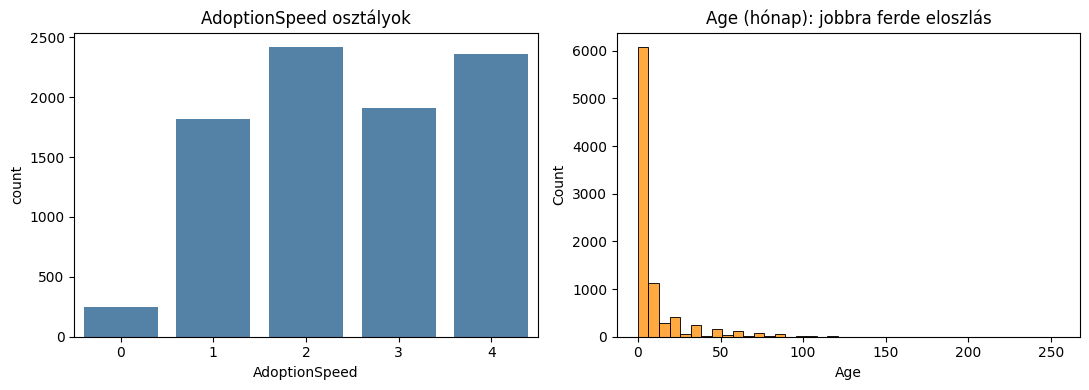

Train osztályarányok (%):


,proportion
AdoptionSpeed,
0,2.8
1,20.8
2,27.6
3,21.8
4,27.0


In [ ]:
# EDA csak a tanítómintákon: a belső tesztet nem használjuk elemzési döntésekhez.
eda = clean_train.iloc[train_idx]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# A célváltozó osztályainak gyakorisága jelzi, hogy nem egyenlő a kategóriák aránya.
sns.countplot(data=eda, x="AdoptionSpeed", ax=ax[0], color="steelblue")
ax[0].set_title("AdoptionSpeed osztályok")
# Az életkor hisztogramja megmutatja a sok fiatal / kevés idős állat mintázatát.
sns.histplot(eda.Age, bins=40, ax=ax[1], color="darkorange")
ax[1].set_title("Age (hónap): jobbra ferde eloszlás")
plt.tight_layout()
plt.savefig(OUT / "eda.png", dpi=150)
plt.show()
print("Train osztályarányok (%):")
display((eda.AdoptionSpeed.value_counts(normalize=True).sort_index() * 100).round(1))


## 5. Új táblázatos jellemzők és transzformációk

### Mit jelent a jellemzők létrehozása?

Az eredeti oszlopokból **10 új, értelmezhető számot** számítunk. Nem kell hozzájuk új adatforrás: minden jellemző az adott hirdetés adataiból adódik. Az eredeti mezőket is megtartjuk, mert a LightGBM maga döntheti el, melyik változat hasznos.

| Új jellemző | Számítás | Jelentés / indoklás |
|---|---|---|
| `Age_Log` | `log(1 + Age)` | A nagy életkorok közötti különbségeket összenyomja; a nulla is érvényes. |
| `Fee_Log` | `log(1 + Fee)` | A nagyon magas díjak hatását mérsékli. |
| `Is_Free` | `Fee == 0` | Megkülönbözteti az ingyenes hirdetéseket. |
| `Is_Group` | `Quantity > 1` | Egyedül vagy csoportban kínált állatot jelez. |
| `Fee_Per_Pet` | `Fee / Quantity` | A díj egy állatra vetített értéke. |
| `Has_Name` | `Name` nem hiányzó | Mennyire teljes a hirdetés. |
| `Is_Mixed` | Másodlagos fajta vagy 307-es első fajtakód | A keverékfajtára utaló információ egyszerű összesítése. |
| `Medical_Yes` | Hány orvosi státusz `1` | A „Yes” válaszok darabszáma a három vizsgált mezőben. |
| `Medical_Unknown` | Hány orvosi státusz `3` | A „Not sure” válaszok darabszáma; nem azonos a „No”-val. |
| `Desc_Words` | `Description` szavainak száma | A hirdetés szövegének hosszát jelzi. |

### Miért biztonságos ez a lépés?

Ezek **soronként determinisztikus** számítások: nem tanulnak átlagot vagy szótárat a többi mintából. Ezért a train/validation/test sorain ugyanazt a szabályt lehet alkalmazni adatszivárgás nélkül. A `Fee_Per_Pet` osztása is biztonságos, mert a 2. részben ellenőriztük, hogy `Quantity > 0`.

**Megjegyzés:** `Age` és `Age_Log` szorosan összefügg; a 9. rész korrelációs ábrája ezt is vizsgálja. Az új jellemzők nem feltétlenül függetlenek egymástól – a kiválasztás külön feladat.


In [ ]:
# Három külön mezőből készítünk összesített egészségügyi állapotjelzőket.
MEDICAL = ["Vaccinated", "Dewormed", "Sterilized"]

# Soronként számított jellemzők: nem kell hozzájuk átlagot vagy más modellt 'fit'-elni.
def add_features(df):
    df = df.copy()
    # log1p(x) = log(1+x), ezért nullára is értelmezett és összenyomja a nagy értékeket.
    df["Age_Log"] = np.log1p(df.Age)
    df["Fee_Log"] = np.log1p(df.Fee)
    df["Is_Free"] = (df.Fee == 0).astype(int)
    df["Is_Group"] = (df.Quantity > 1).astype(int)
    # A díjat az állatok darabszámára vetítjük; Quantity>0 már ellenőrzött.
    df["Fee_Per_Pet"] = df.Fee / df.Quantity
    df["Has_Name"] = df.Name.notna().astype(int)
    df["Is_Mixed"] = ((df.Breed2 > 0) | (df.Breed1 == 307)).astype(int)
    df["Medical_Yes"] = df[MEDICAL].eq(1).sum(axis=1)
    # A bizonytalan (3-as) orvosi státuszt nem keverjük össze a nem (2-es) válasszal.
    df["Medical_Unknown"] = df[MEDICAL].eq(3).sum(axis=1)
    df["Desc_Words"] = df.Description.str.split().str.len()
    return df

tab_train, tab_test = add_features(clean_train), add_features(clean_test)
print("Új táblázatos jellemzők:", sorted(set(tab_train) - set(clean_train)))


Új táblázatos jellemzők: ['Age_Log', 'Desc_Words', 'Fee_Log', 'Fee_Per_Pet', 'Has_Name', 'Is_Free', 'Is_Group', 'Is_Mixed', 'Medical_Unknown', 'Medical_Yes']


## 6. Szöveges jellemzők: TF–IDF és TruncatedSVD

### Miért dolgozzuk fel a `Description` mezőt?

A leírás tartalmazhat olyan információt (például állat temperamentuma, körülmények, gondozási igény), amelyet a táblázatos oszlopok nem írnak le. A gépi tanulási modell viszont szöveg helyett számokat vár.

### Hogyan készül a 10 szöveges jellemző?

1. **TF–IDF (Term Frequency – Inverse Document Frequency):** minden hirdetés leírását szavakhoz tartozó számsorrá alakítja. A nagyon sok dokumentumban előforduló szavak kisebb súlyt kapnak, az egyedi, jellemző szavak nagyobbat.
2. **`max_features=3000`:** legfeljebb 3000 szót tartunk meg, hogy kezelhető legyen a reprezentáció mérete.
3. **`min_df=2`:** csak olyan szavak maradnak, amelyek legalább két tanító leírásban előfordulnak; az egyszeri elütéseket így könnyebben kiszűrjük.
4. **`stop_words='english'`:** a gyakori angol töltelékszavakat kiszűrjük. Ez egyszerű közelítés, mert az adatbázisban más nyelvű leírások is lehetnek.
5. **TruncatedSVD:** a ritka, akár 3000 dimenziós szóvektorokat **10 sűrű numerikus komponensre** tömöríti (`Text_0` … `Text_9`). Ez a módszer a szövegben együtt megjelenő szavak mintázatait foglalhatja össze.

### Hol akadályozzuk meg az adatszivárgást?

A `tfidf.fit_transform()` és az `svd.fit()` **csak** a 8 751 tanító mintán fut. Az összes többi adatra kizárólag `transform()` történik, tehát a validation és a belső test **nem alakítja a tanult szótárat vagy az SVD irányait**.

**Tényleges eredmény:** 3000 elemű szótár; az első 10 szöveges SVD-komponens összesen **10,6% magyarázott varianciát** ad. Ez érezhető információvesztést jelez, ezért a 10 dimenzió **egyszerűségi kompromisszum**, nem állítás arról, hogy minden szöveges információt megőriztünk.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# A szövegeket szógyakoriság- és ritkaságsúlyozott számmátrixszá alakítjuk.
tfidf = TfidfVectorizer(max_features=3000, min_df=2, stop_words="english")
# A max. 3000 szódimenziót 10 összefoglaló dimenzióra csökkentjük.
svd = TruncatedSVD(n_components=10, random_state=SEED)
# Kulcsszabály: a szótárt csak a belső TRAIN szövegeiből tanuljuk meg!
train_tfidf = tfidf.fit_transform(clean_train.iloc[train_idx].Description)
# Az SVD irányai sem láthatják a validation vagy tesztsorokat az illesztésnél.
svd.fit(train_tfidf)

# A többi részhalmazra már kizárólag a megtanult transzformációt alkalmazzuk.
def text_table(df):
    data = svd.transform(tfidf.transform(df.Description))
    return pd.DataFrame(data, columns=[f"Text_{i}" for i in range(10)])

text_train, text_test = text_table(clean_train), text_table(clean_test)
print("TF-IDF szótárméret:", len(tfidf.vocabulary_))
print("10 SVD komponens magyarázott varianciája:", f"{svd.explained_variance_ratio_.sum():.1%}")


TF-IDF szótárméret: 3000
10 SVD komponens magyarázott varianciája: 10.6%


## 7. Képi jellemzők: előre tanított, befagyasztott ResNet50

### Mit és miért dolgozunk fel?

Az állat megjelenése – például bundája vagy a fotón látható környezet – olyan jelzés lehet, amely a CSV-ben nem szerepel. A kód ezért minden hirdetés **első fotóját** keresi (`PetID-1.jpg`). Ez jelentős egyszerűsítés: a további fotók információját nem használjuk fel.

### Hogyan lesz egy képből számoszlop?

1. A **ResNet50** egy konvolúciós neurális hálózat. Az ImageNet-adatkészleten már betanított `IMAGENET1K_V2` súlyokat töltjük be, ezért itt **nem tanítunk új képfelismerő hálózatot**.
2. A végső, ImageNet-osztályokat megjósló réteget `Identity()` rétegre cseréljük. Így a hálózat minden képre **2048 elemű jellemzővektort** ad, nem pedig egy állatfajtát jósol.
3. Az előfeldolgozás (`weights.transforms()`) átméretezi/vágja és normalizálja a képet a betanításhoz illeszkedő módon.
4. `eval()` és `requires_grad_(False)` befagyasztja a hálózat működését; `torch.inference_mode()` kikapcsolja a gradiensszámítást. A képeket **16-os csomagokban** dolgozzuk fel; GPU esetén a `cuda` eszközt használjuk.
5. A 2048 jellemző sok lenne egy könnyen értelmezhető beadandóhoz. Egy **csak belső trainre illesztett TruncatedSVD** a vektort 10 `Image_*` komponensre csökkenti; a `Has_Image` jelzi, van-e olvasható fotó.

### Mitől reprodukálható?

A súlyverzió és a véletlen kezdőérték rögzített. A már kiszámolt képi vektorokat `.npz` állományban tároljuk (`PetID`-sorrend ellenőrzéssel), ezért újrafuttatáskor nem szükséges megismételni a lassú neurális hálózati lépést. Az esetleges sérült/hiányzó képhez nullvektor és hiányjelző tartozik.

**Tényleges eredmény:** a 14 993 címkézett hirdetésből **14 652-höz** készült olvasható első kép (kb. 97,7%). A 10 képi komponens **36,1% magyarázott varianciát** őriz meg. Ez tömör reprezentáció, tehát információt veszít.

**Fontos korlát:** a képfeldolgozás a beadandóhoz **nem kötelező**. A 10. részben a kép nélküli modell kontrollként szerepel; a képek hasznosságát nem feltételezzük előre, hanem a validation eredményeiből vizsgáljuk.


In [ ]:
from io import BytesIO
from PIL import Image
from tqdm.auto import tqdm
import torch
import torchvision
from torchvision import models

# GPU-t használunk, ha elérhető; különben a CPU is működik (lassabban).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Pontos, előre betanított ImageNet-súlyverzió – a futás nem tanítja újra.
weights = models.ResNet50_Weights.IMAGENET1K_V2  # Konkrét súlyverzió: reprodukálható.
encoder = models.resnet50(weights=weights)
# Levesszük az ImageNet-osztályozó fejet: 1000 osztály helyett 2048 képi jellemző kell.
encoder.fc = torch.nn.Identity()  # A végső osztályozó helyett 2048 képi jellemző.
# eval + requires_grad_(False): befagyasztott, csak következtetésre használt hálózat.
encoder = encoder.to(device).eval().requires_grad_(False)
preprocess = weights.transforms()
print("ResNet50 eszköz:", device)

# Minden állat első JPEG-fotójához tárolunk egy 2048 elemű vektort.
def image_vectors(df, split):
    cache = OUT / f"{split}_resnet50_first_image.npz"
    pet_ids = df.PetID.astype(str).to_numpy()
    # Korábban számított eredmény: a PetID-sorrend ellenőrzése után újrafelhasználható.
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert np.array_equal(saved["pet_ids"], pet_ids), "Megváltozott a sorok sorrendje."
            return saved["vectors"], saved["has_image"]

    archive = kaggle_download(f"{split}_images.zip")
    vectors = np.zeros((len(df), 2048), dtype=np.float32)
    has_image = np.zeros(len(df), dtype=np.int8)
    batch, positions = [], []

    # Egyszerre legfeljebb 16 képet futtatunk a ResNet50-en, gradiensszámítás nélkül.
    def process_batch():
        if batch:
            with torch.inference_mode():
                output = encoder(torch.stack(batch).to(device)).cpu().numpy()
            vectors[positions] = output
            batch.clear()
            positions.clear()

    # Nem bontunk ki minden JPEG-et: a ZIP-ből közvetlenül olvassuk az első képeket.
    with zipfile.ZipFile(archive) as z:
        # A ZIP belső mappanevétől függetlenül megtaláljuk az első képet.
        image_names = {Path(n).name[:-6]: n for n in z.namelist()
                       if Path(n).name.endswith("-1.jpg")}
        for i, pet_id in enumerate(tqdm(pet_ids, desc=f"{split} képek")):
            name = image_names.get(pet_id)
            if name is None:
                continue
            try:
                with z.open(name) as f:
                    picture = Image.open(BytesIO(f.read())).convert("RGB")
                batch.append(preprocess(picture))
                positions.append(i)
                has_image[i] = 1
                if len(batch) == 16:
                    process_batch()
            except (OSError, ValueError):
                has_image[i] = 0  # Olvashatatlan kép: külön hiányjelző.
        process_batch()

    # A lassú jellemzőkinyerést fájlba mentjük, hogy egy újabb futás gyorsabb legyen.
    np.savez_compressed(cache, pet_ids=pet_ids, vectors=vectors, has_image=has_image)
    return vectors, has_image

raw_img_train, has_train_image = image_vectors(raw_train, "train")
raw_img_test, has_test_image = image_vectors(raw_test, "test")
image_svd = TruncatedSVD(n_components=10, random_state=SEED)
# Szivárgásvédelem: a képi dimenziócsökkentő csak a belső trainen illeszkedik.
image_svd.fit(raw_img_train[train_idx])  # Csak a belső trainből tanulunk.

def image_table(vectors, indicator):
    df = pd.DataFrame(image_svd.transform(vectors),
                      columns=[f"Image_{i}" for i in range(10)])
    df["Has_Image"] = indicator
    return df

image_train = image_table(raw_img_train, has_train_image)
image_test = image_table(raw_img_test, has_test_image)
print("Olvasható első fényképek:", int(has_train_image.sum()), "/", len(raw_train))
print("Képi SVD (10 komponens) magyarázott varianciája:",
      f"{image_svd.explained_variance_ratio_.sum():.1%}")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 129MB/s]


ResNet50 eszköz: cuda


train képek:   0%|          | 0/14993 [00:00<?, ?it/s]

test képek:   0%|          | 0/3972 [00:00<?, ?it/s]

Olvasható első fényképek: 14652 / 14993
Képi SVD (10 komponens) magyarázott varianciája: 36.1%


## 8. A különböző jellemzők egyesítése

### Mit csinálunk?

Egyetlen, a LightGBM számára használható adattáblába egyesítjük:

- az eredeti és a **10 új táblázatos jellemzőt**;
- a **10 szöveges SVD-komponenst**;
- a **10 képi SVD-komponenst és a `Has_Image` jelzőt**.

Az eredeti táblában található `Name` és `Description` nyers szöveget már feldolgoztuk, ezért nem küldjük közvetlenül a LightGBM-nek. Az azonosítóként szolgáló `PetID` és `RescuerID`, valamint a megjósolandó `AdoptionSpeed` szintén **nem** lehet bemeneti oszlop. Ez alapvető adatszivárgás elleni védelem.

### Miért fontos a kategorikus adattípus?

A `Breed1`, `Color1`, `State` stb. oszlopokban a számok **kategóriakódok**, nem valódi mennyiségek. Például a 300-as fajtakód nem „háromszor akkora”, mint a 100-as. A `.astype(pd.CategoricalDtype(...))` jelzi a LightGBM számára, hogy az oszlop kategóriákat tartalmaz.

Az ismert kategóriák listáját **kizárólag a belső trainből** vesszük; az ismeretlen validation/test értékek hiányzó kategóriaként kezelhetők, nem kerülnek utólag a tanító kategórialexikonba.

### Mit mutat az eredmény?

**Train: 8 751 × 50**, validation: **3 053 × 50**, belső test: **3 189 × 50**. Az 50 a modellnek átadott jellemzők darabszáma, **nem** az eredeti Kaggle-tábla oszlopszáma. A sorok sorrendjének egyeztetését `reset_index(drop=True)` biztosítja, mert a szöveges és képi táblák sorpozíció szerint kerülnek egymás mellé.


In [ ]:
# Ezek a számmal jelölt oszlopok valójában KATEGÓRIÁK, nem folytonos mérési értékek.
CATEGORIES = ["Type", "Breed1", "Breed2", "Gender", "Color1", "Color2",
              "Color3", "State", "MaturitySize", "FurLength", "Health",
              "Vaccinated", "Dewormed", "Sterilized"]
# Nyers szöveg, azonosítók és célváltozó nem kerülhetnek közvetlenül a modellbemenetbe.
REMOVE = ["PetID", "RescuerID", "Name", "Description", "AdoptionSpeed"]

# Egységes sorrendben összefűzzük a táblázatos, szöveges és képi jellemzőket.
def combine(table, text, image):
    numeric = table.drop(columns=REMOVE, errors="ignore").reset_index(drop=True)
    return pd.concat([numeric, text.reset_index(drop=True), image.reset_index(drop=True)], axis=1)

features = combine(tab_train, text_train, image_train)
kaggle_features = combine(tab_test, text_test, image_test)
# A lehetséges kategóriaértékeket csak a belső TRAIN sorai alapján határozzuk meg.
for col in CATEGORIES:
    # A kategóriák lehetséges értékei kizárólag a belső trainből származnak.
    cats = sorted(features.iloc[train_idx][col].dropna().unique())
    dtype = pd.CategoricalDtype(categories=cats)
    features[col] = features[col].astype(dtype)
    kaggle_features[col] = kaggle_features[col].astype(dtype)

# Az indexek szétválasztják a 3 részhalmazt; a sorok egyezését lent ellenőrizzük.
X_train = features.iloc[train_idx].reset_index(drop=True)
X_val = features.iloc[val_idx].reset_index(drop=True)
X_test = features.iloc[test_idx].reset_index(drop=True)
y_train = clean_train.AdoptionSpeed.iloc[train_idx].reset_index(drop=True)
y_val = clean_train.AdoptionSpeed.iloc[val_idx].reset_index(drop=True)
y_test = clean_train.AdoptionSpeed.iloc[test_idx].reset_index(drop=True)
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert not any(c in X_train for c in ("PetID", "RescuerID", "AdoptionSpeed"))
print(f"Train: {X_train.shape}, validation: {X_val.shape}, belső test: {X_test.shape}")


Train: (8751, 50), validation: (3053, 50), belső test: (3189, 50)


## 9. Előzetes jellemzőelemzés: korrelációk

### Mit mér a Spearman-korreláció?

Két numerikus oszlop között azt vizsgálja, mennyire járnak együtt az értékek **sorrendjei**. Az eredmény –1 és +1 közötti: közel +1 esetén együtt nőnek, közel –1 esetén ellentétes irányban mozognak, 0 körül nincs erős monoton kapcsolat.

### Mely jellemzőket és miért hasonlítjuk össze?

- `Age` és `Age_Log`, illetve `Fee` és `Fee_Log`: mivel a logaritmus monoton növő, a Spearman-korrelációjuk várhatóan **nagyon közel +1-hez**, ideális esetben pontosan +1-hez esik. Ez tudatosan létrehozott redundancia.
- `Fee`, `Quantity`, `Fee_Per_Pet`: a három változó számításilag összefügg, ezért érdemes látni kapcsolatukat.
- `PhotoAmt`, `Desc_Words`, `Medical_Yes`: különböző információtípusokat reprezentálnak.

**Miért csak a trainen?** Az előzetes elemzés nem használhatja fel a belső teszt eloszlását modellfejlesztésre.

**Mit nem állíthatunk?** Erős korreláció nem bizonyít ok-okozati kapcsolatot vagy azt, hogy az egyik változót feltétlenül el kell hagyni. A LightGBM nemlineáris összefüggéseket is felismer; ezért a tényleges jellemzőkiválasztás a következő részben történik.


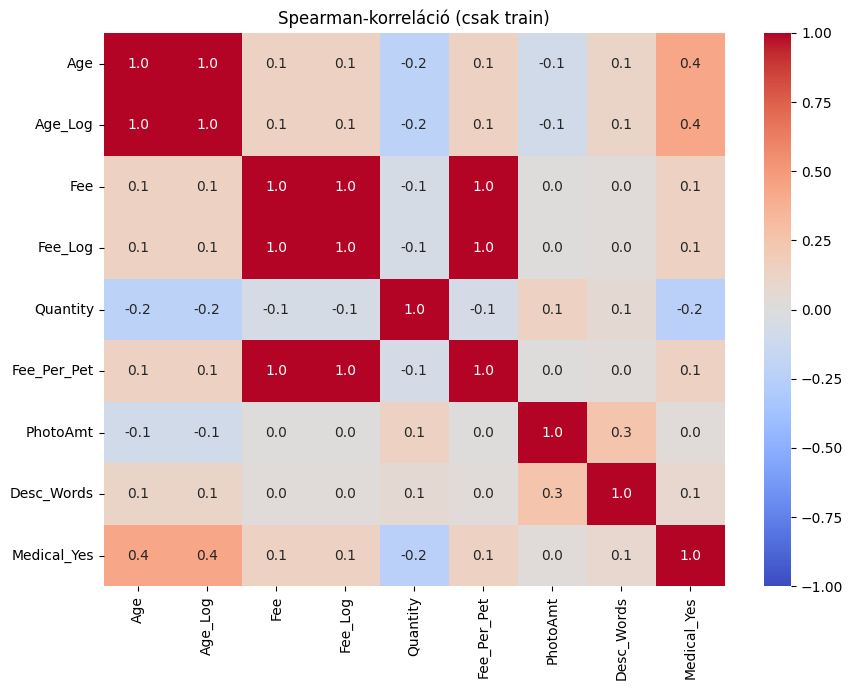

In [ ]:
# Néhány könnyen értelmezhető numerikus oszlop redundanciáját vizsgáljuk.
check_cols = ["Age", "Age_Log", "Fee", "Fee_Log", "Quantity",
              "Fee_Per_Pet", "PhotoAmt", "Desc_Words", "Medical_Yes"]
# Spearman: a sorrendek együttmozgását méri; a log-transzformáció sem változtatja a sorrendet.
corr = X_train[check_cols].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman-korreláció (csak train)")
plt.tight_layout()
plt.savefig(OUT / "feature_correlations.png", dpi=150)
plt.show()


## 10. Jellemzők kiválasztása és modellek összehasonlítása

### Miért LightGBM?

A **LightGBM** sok, egymást kiegészítő döntési fából álló modell. Vegyes numerikus és kategorikus adatokkal jól használható, és az oszlopok fontosságáról egyszerűen képes kimutatást készíteni. A választott `gain` fontosság azt összegzi, hogy egy jellemző a tanítási fafelosztásokban mennyivel csökkentette a tanítási hibát. **Nem oksági hatást mér.**

### A hiperparaméterek indoklása

- `objective='multiclass'`, `num_class=5`: öt lehetséges kategóriából választunk.
- `n_estimators=100`: 100 boosting-iteráció; többosztályos feladatban iterációnként több fa is készülhet. Ez gyors, könnyen reprodukálható kiindulópont.
- `learning_rate=0.05`: minden új fa viszonylag kis korrekciót ad.
- `num_leaves=15`: viszonylag kisméretű fákat enged, hogy ne legyen indokolatlanul bonyolult a modell.
- `class_weight='balanced'`: a ritka 0-s osztály nagyobb súlyt kaphat. Ez javíthatja a ritka osztály figyelembevételét, de közben a pontosságot akár ronthatja.
- `random_state=42`, `n_jobs=2`: rögzített véletlen működés és visszafogott párhuzamosítás.

**Nem végeztünk széles hiperparaméter-hangolást**: ebben a mérföldkőben a jellemzők kezelésének és összehasonlításának bemutatása a cél.

### Milyen három modellt hasonlítunk össze?

1. **Táblázat + szöveg:** a képfeldolgozás nélküli, egyszerűbb összehasonlítási alap.
2. **Táblázat + szöveg + kép:** mind az 50 jellemzővel dolgozik.
3. **Top 20:** a *teljes modell tanítóhalmazon számolt* `gain` rangsorának első 20 jellemzőjét használja.

Mindhárom modellt ugyanazon a trainen illesztjük, ugyanazon a validationön értékeljük. A legjobb változatot **QWK alapján** választjuk, mert a 0–4 célváltozó sorrenddel rendelkezik: súlyosabb tévedés a 0 helyett 4-et jósolni, mint a 0 helyett 1-et. Emellett megadjuk a **Macro-F1**-et (az öt osztály F1-értékének átlaga) és az **Accuracy**-t (helyes találatok aránya).

### A tényleges validációs eredmények

| Jellemzők | QWK | Macro-F1 | Accuracy |
|---|---:|---:|---:|
| Táblázat + szöveg | **0,3266** | **0,3108** | **0,3767** |
| Táblázat + szöveg + kép | **0,3421** | 0,3021 | 0,3682 |
| Top 20 | 0,3051 | 0,2865 | 0,3492 |

**Következtetés:** a képek hozzáadása a **QWK-t 0,0155-tel javította**, de a Macro-F1 és az Accuracy **romlott**. Tehát a képek nem „minden szempontból jobbak”: a választás kizárólag a **előre megadott QWK-elsőbbség** mellett indokolható. A Top 20 jellemző ebben a beállításban kevésnek bizonyult. A validáción a **teljes, 50 jellemzős változat** nyert.


,QWK,Macro-F1,Accuracy
Táblázat + szöveg,0.3266,0.3108,0.3767
Táblázat + szöveg + kép,0.3421,0.3021,0.3682
Top 20,0.3051,0.2865,0.3492


Választott modell: Táblázat + szöveg + kép | Felhasznált jellemzők: 50


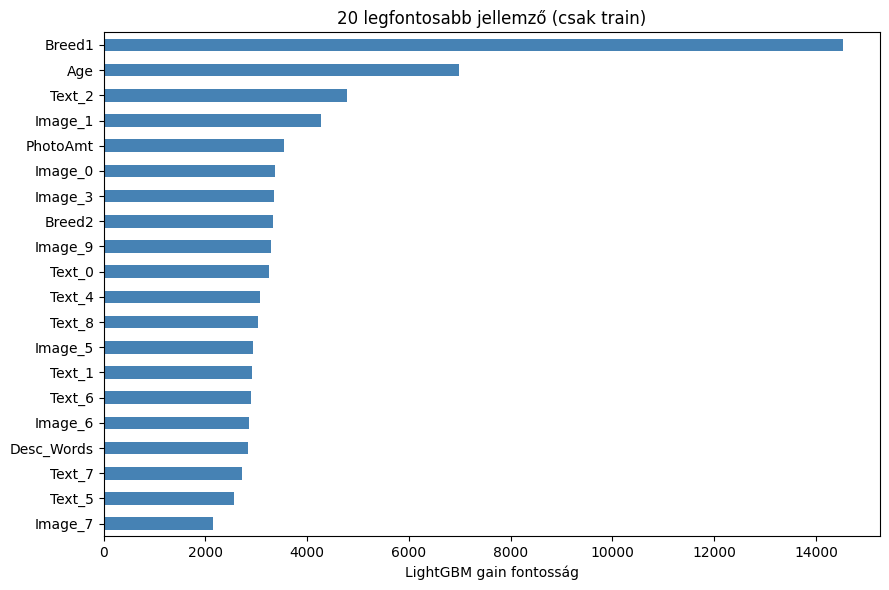

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Mindhárom változathoz azonos LightGBM-beállításokat alkalmazunk: így korrekt az összevetés.
def fit_model(columns, data, labels):
    # Kicsi fa (15 levél), 100 iteráció, ritka osztályok súlyozása, rögzített seed.
    model = lgb.LGBMClassifier(
        objective="multiclass", num_class=5, n_estimators=100,
        learning_rate=0.05, num_leaves=15, class_weight="balanced",
        random_state=SEED, n_jobs=2, verbosity=-1, importance_type="gain")
    model.fit(data[columns], labels,
              categorical_feature=[c for c in CATEGORIES if c in columns])
    return model

# QWK: 0-4 sorrendet figyelembe veszi; Macro-F1: osztályokat egyenlően kezeli.
def scores(true, pred):
    return {"QWK": cohen_kappa_score(true, pred, weights="quadratic"),
            "Macro-F1": f1_score(true, pred, average="macro", zero_division=0),
            "Accuracy": accuracy_score(true, pred)}

all_cols = X_train.columns.tolist()
# Kontroll: mindent megtartunk, kivéve a ResNet50-ből származó jellemzőket.
without_image = [c for c in all_cols if not (c.startswith("Image_") or c == "Has_Image")]
baseline_model = fit_model(without_image, X_train, y_train)
full_model = fit_model(all_cols, X_train, y_train)
# Gain fontosság kizárólag a trainen tanított teljes modellből származik.
importance = pd.Series(full_model.feature_importances_, index=all_cols).sort_values(ascending=False)
# A húsz legfontosabb oszlopból egy új, kisebb modellt is tanítunk.
selected_cols = importance.head(20).index.tolist()
small_model = fit_model(selected_cols, X_train, y_train)

# Azonos validation adatokon 3 jellemzőkészletet hasonlítunk össze.
comparison = pd.DataFrame({
    "Táblázat + szöveg": scores(y_val, baseline_model.predict(X_val[without_image])),
    "Táblázat + szöveg + kép": scores(y_val, full_model.predict(X_val[all_cols])),
    "Top 20": scores(y_val, small_model.predict(X_val[selected_cols])),
}).T
display(comparison.round(4))
comparison.to_csv(OUT / "validation_results.csv")
importance.rename("Gain importance").to_csv(OUT / "feature_importance.csv")

# A választás szabályát előre rögzítjük: a legnagyobb VALIDÁCIÓS QWK nyer.
best = comparison["QWK"].idxmax()
best_model = {"Táblázat + szöveg": baseline_model,
              "Táblázat + szöveg + kép": full_model,
              "Top 20": small_model}[best]
best_cols = {"Táblázat + szöveg": without_image,
             "Táblázat + szöveg + kép": all_cols,
             "Top 20": selected_cols}[best]
print("Választott modell:", best, "| Felhasznált jellemzők:", len(best_cols))

plt.figure(figsize=(9, 6))
importance.head(20).sort_values().plot.barh(color="steelblue")
plt.xlabel("LightGBM gain fontosság")
plt.title("20 legfontosabb jellemző (csak train)")
plt.tight_layout()
plt.savefig(OUT / "feature_importance.png", dpi=150)
plt.show()


## 11. Egyszeri, érintetlen belső tesztértékelés

### Mi a belső test szerepe?

A validation eredménye alapján **már kiválasztottuk** a modellt (mind az 50 jellemzőt használó LightGBM). A belső teszten ezért **nem keresünk új beállítást**, csak megnézzük, hogyan teljesít egy másik, korábban nem használt hirdetéshalmazon, amelynek megmentői sem szerepeltek a tanítóhalmazban.

### Mit jelentenek a három fő mérőszám eredményei?

- **QWK = 0,3217:** a modell a véletlen egyezés fölött teljesít, de a kategóriák sorrendjét figyelembe véve az eredmény még mérsékelt. A validation 0,3421-es QWK-jához képest kisebb visszaesés látható.
- **Macro-F1 = 0,2959:** az öt kategória átlagos F1-pontszáma; az osztályegyenlőtlenség mellett informatívabb, mint önmagában a pontosság.
- **Accuracy = 0,3496:** az érintetlen belső teszt hirdetéseinek kb. 35%-ánál találta el pontosan a címkét.

### Hogyan olvassuk az osztályonkénti táblázatot?

Az F1 a **precision** (a pozitívnak jósoltak között mennyi volt valóban oda tartozó) és a **recall** (a valódi osztálytagok mekkora részét találjuk meg) harmonikus közepe. A `support` az adott valódi osztály darabszáma.

A **0-s osztálynál** a precision **0,05**, a recall **0,18**, az F1 **0,08** – vagyis ez kifejezetten nehéz kategória. A **4-es osztály** F1-értéke **0,52**, lényegesen jobb. A konfúziós mátrix segít megnézni, mely kategóriákat keverjük össze.

**Korlát:** ez egyetlen csoportos felosztáson, egyetlen modellen mért belső teszt. Nem helyettesíti a többszörös keresztvalidációt vagy a Kaggle rejtett tesztjének külön kiértékelését; a belső teszt eredménye alapján azonban **nem szabad újabb modellt választani**, mert az már rontaná a teszt függetlenségét.


Belső teszt: {'QWK': np.float64(0.3217), 'Macro-F1': 0.2959, 'Accuracy': 0.3496}
              precision    recall  f1-score   support

           0       0.05      0.18      0.08        91
           1       0.32      0.41      0.36       612
           2       0.33      0.20      0.25       856
           3       0.34      0.23      0.27       747
           4       0.48      0.57      0.52       883

    accuracy                           0.35      3189
   macro avg       0.30      0.32      0.30      3189
weighted avg       0.36      0.35      0.35      3189



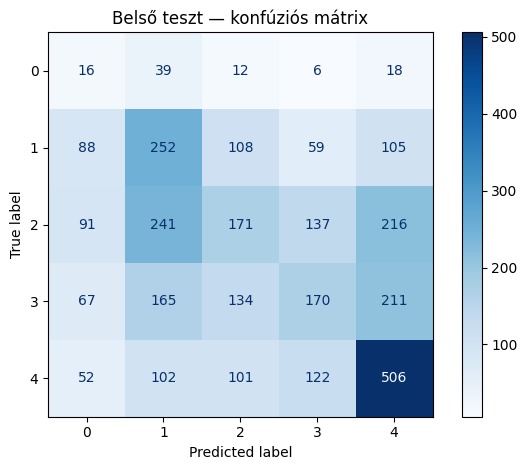

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# A modellvariáns már eldőlt: itt egyszer mérünk a félretett belső teszten.
test_pred = best_model.predict(X_test[best_cols])
print("Belső teszt:", {k: round(v, 4) for k, v in scores(y_test, test_pred).items()})
# Precision/recall/F1 osztályonként: különösen a ritka 0-s kategóriát nézzük.
print(classification_report(y_test, test_pred, labels=[0, 1, 2, 3, 4],
                            zero_division=0))

# Sor: valódi címke, oszlop: jósolt címke – jól láthatók a gyakori összekeverések.
ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
    labels=[0, 1, 2, 3, 4], cmap="Blues", values_format="d")
plt.title("Belső teszt — konfúziós mátrix")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=150)
plt.show()
pd.DataFrame({"PetID": clean_train.PetID.iloc[test_idx].to_numpy(),
              "true": y_test, "pred": test_pred}).to_csv(
              OUT / "internal_test_predictions.csv", index=False)


## 12. A jellemzőtér vizsgálata: PCA és t-SNE

### Miért szeretnénk két dimenzióra vetíteni?

Az 50 oszlopos jellemzőtér közvetlenül nem ábrázolható. A dimenziócsökkentéssel minden tanító hirdetésből egy **(x, y) koordinátát** készítünk, és színnel jelöljük a valódi `AdoptionSpeed` kategóriát. Így szemléletesen megvizsgálhatjuk, láthatók-e elkülönülő csoportok vagy átfedések.

### Az előfeldolgozás logikája

1. A **kategorikus oszlopokat one-hot kódoljuk** (`get_dummies`), mert a távolság-alapú vizualizációhoz a kategóriák nem használhatók egyszerű sorszámként.
2. A hiányzó numerikus értékeket az adott tanító adat középértékeivel pótoljuk, majd a megmaradt hiányokat nullával töltjük.
3. A **StandardScaler** a numerikus oszlopokat a tanító adat átlagához és szórásához viszonyítja; különben a nagyobb mértékegységű változók dominálhatnák a vetítést.

### PCA és t-SNE között mi a különbség?

- **PCA:** lineáris eljárás; két olyan irányt keres, amely a lehető legtöbb teljes varianciát őrzi meg. A teljes tanítóhalmazra számítjuk.
- **t-SNE:** nemlineáris eljárás; főleg a közeli pontok szomszédsági viszonyait törekszik megőrizni. A számításigény miatt **legfeljebb 1500 véletlenül kiválasztott train ponton** használjuk; a `perplexity=30` az eljárás helyi szomszédsági skáláját befolyásolja.

### Mi következik a kimenetből?

A PCA első két komponense csak **3,7% magyarázott varianciát** fed le. Így az ábrán látható átfedésekből **nem** következtethetünk arra, hogy az összes eredeti jellemző alapján biztosan rosszul elkülöníthetők az osztályok. A t-SNE-n a tengelyeknek nincs közvetlen gyakorlati jelentése; a csoportok méretét és egymástól való távolságát óvatosan kell értelmezni.

**Fontos:** ezek a vetítések **csak az ábrákat szolgálják**. A LightGBM tanítási bemenetébe nem kerülnek vissza, így nincs külön PCA/t-SNE-alapú predikció.


PCA első két komponensének magyarázott varianciája: 3.7%


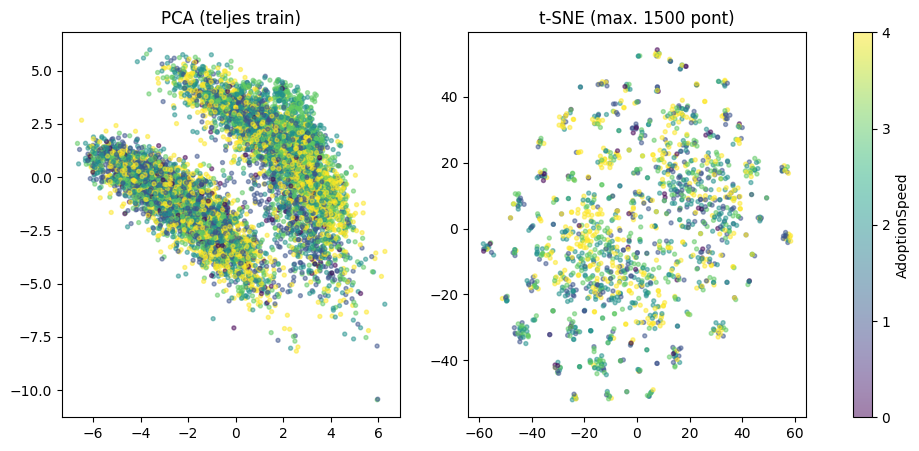

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# A PCA/t-SNE ábrákhoz minden kategória külön 0/1 jelzőt kap.
# A kategóriakódokat külön 0/1 oszlopokra bontjuk a távolságalapú módszerekhez.
plot_data = pd.get_dummies(X_train[best_cols], dtype=float)
plot_data = plot_data.fillna(plot_data.median()).fillna(0)
# Skálázunk, hogy a nagy számértékű változók ne dominálják a vetítést.
scaled = StandardScaler().fit_transform(plot_data)

# A PCA lineáris, maximális varianciát őrző kétdimenziós vetítés.
pca = PCA(n_components=2, random_state=SEED)
pca_xy = pca.fit_transform(scaled)
print("PCA első két komponensének magyarázott varianciája:",
      f"{pca.explained_variance_ratio_.sum():.1%}")

# A t-SNE számításigénye miatt legfeljebb 1500 tanítópontot ábrázolunk.
n = min(1500, len(scaled))
sample = np.random.default_rng(SEED).choice(len(scaled), n, replace=False)
# A t-SNE főleg a közeli pontok kapcsolatát mutatja, nem globális távolságokat.
tsne_xy = TSNE(n_components=2, perplexity=30, init="pca",
               learning_rate="auto", random_state=SEED).fit_transform(scaled[sample])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, xy, target, title in [
    (axs[0], pca_xy, y_train, "PCA (teljes train)"),
    (axs[1], tsne_xy, y_train.iloc[sample], "t-SNE (max. 1500 pont)")]:
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=target, s=8,
                    cmap="viridis", alpha=0.5, vmin=0, vmax=4)
    ax.set_title(title)
fig.colorbar(sc, ax=axs, ticks=[0, 1, 2, 3, 4], label="AdoptionSpeed")
plt.savefig(OUT / "feature_space.png", dpi=150, bbox_inches="tight")
plt.show()


## 13. A választott modell újratanítása és a fájlok mentése

### Miért tanítunk még egy modellt?

A train/validation/belső test szétválasztás a **becsületes modellválasztáshoz és ellenőrzéshez** kellett. Miután ezt lezártuk, a Kaggle címkézetlen tesztjére történő predikcióhoz már kihasználhatjuk a **teljes 14 993 soros címkézett train.csv-t**. A korábban kiválasztott 50 bemeneti jellemzőt és a rögzített LightGBM-beállításokat tartjuk meg.

### Milyen fájlok készülnek?

| Fájl | Mire használható? |
|---|---|
| `data_quality_before_after.csv` | Tisztítás előtti–utáni számlálások |
| `split_manifest.csv` | A train/validation/test hirdetések pontos listája |
| `validation_results.csv` | A három jellemzőváltozat pontszámai |
| `feature_importance.csv` | LightGBM `gain` fontosságok |
| `train_features.csv`, `validation_features.csv`, `internal_test_features.csv` | A kiválasztott modellhez tartozó feldolgozott adatok |
| `internal_test_predictions.csv` | A belső teszt valódi és jósolt címkéi |
| `submission.csv` | A Kaggle hivatalos test soraihoz készített predikciók (`PetID`, `AdoptionSpeed`) |
| `pipeline_parts.joblib` | Modellek, TF–IDF, szöveges/képi SVD és jellemzőlista |
| `run_summary.json` | Könyvtárverziók, választott modell és pontszámok |
| `.png` ábrák | EDA, korreláció, fontosság, konfúziós mátrix, jellemzőtér |

### Mire kell figyelni a reprodukálásnál?

- A `submission.csv` **nem mért Kaggle-pontszám**; a hivatalos test címkéi nélkül helyben nem is számolható rajta QWK.
- A `pipeline_parts.joblib` **nem teljes, egyetlen hívással futtatható képfeldolgozó pipeline**: a képek feldolgozásához az eredeti ZIP, a notebook ResNet50-kódja és a rögzített ImageNet-súlyverzió is szükséges.
- A szöveges és képi SVD a korábbi **belső trainen lett illesztve**, majd változatlanul alkalmazzuk minden adatra. A végső LightGBM viszont már **a teljes címkézett halmazon** tanul. Ez megőrzi az összehasonlított reprezentációt, bár nem használja ki a teljes train adatait az SVD/TF–IDF újraillesztéséhez.
- A kód az `OUT = /content/petfinder_m2_results` mappába ment: ezt Colabból külön le kell tölteni vagy Drive-ra kell másolni, ha hosszú távon meg akarjuk őrizni.


In [ ]:
import json
import joblib
import sklearn

# Elmentjük az egyes részhalmazok kiválasztott jellemzőit a hozzájuk tartozó címkékkel.
def save_split(x, target, name):
    result = x[best_cols].copy()
    result["AdoptionSpeed"] = target.to_numpy()
    result.to_csv(OUT / f"{name}_features.csv", index=False)

save_split(X_train, y_train, "train")
save_split(X_val, y_val, "validation")
save_split(X_test, y_test, "internal_test")

# A belső teszt lezárása után ugyanazt a modellt a TELJES címkézett trainen tanítjuk.
final_model = fit_model(best_cols, features, clean_train.AdoptionSpeed)
# A hivatalos Kaggle-tesztnek nincs célcímkéje: csak becsült osztályokat készítünk.
kaggle_pred = final_model.predict(kaggle_features[best_cols])
pd.DataFrame({"PetID": raw_test.PetID, "AdoptionSpeed": kaggle_pred}).to_csv(
    OUT / "submission.csv", index=False)
# A modell és a szöveges/képi dimenziócsökkentők mentése a későbbi felhasználáshoz.
joblib.dump({"internal_test_model": best_model, "kaggle_model": final_model,
             "tfidf": tfidf, "text_svd": svd, "image_svd": image_svd,
             "selected_columns": best_cols}, OUT / "pipeline_parts.joblib")
# Seed, verziók, választott jellemzők és mérőszámok: dokumentálható kísérleti napló.
with open(OUT / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "split": "StratifiedGroupKFold / RescuerID",
               "versions": {"python": sys.version.split()[0], "pandas": pd.__version__,
                            "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__,
                            "torch": torch.__version__, "torchvision": torchvision.__version__},
               "image_features": {"model": "ResNet50 ImageNet-1K V2, frozen",
                                  "first_image_only": True,
                                  "train_images_found": int(has_train_image.sum()),
                                  "train_total": len(raw_train)},
               "selected_variant": best, "selected_columns": best_cols,
               "validation": comparison.to_dict(orient="index"),
               "internal_test": scores(y_test, test_pred)}, f, indent=2)
print("Az eredmények helye:", OUT)
print("Elmentett Kaggle submission:", OUT / "submission.csv")


Az eredmények helye: /content/petfinder_m2_results
Elmentett Kaggle submission: /content/petfinder_m2_results/submission.csv


## 14. Összefoglalás

### Mit valósítottunk meg?

1. **Helyes adatfelosztás:** megmentő (`RescuerID`) szerint elkülönített train, validation és belső test, körülbelül 60/20/20 arányban. Így a megmentőkhöz kötődő hasonlóság kevésbé torzítja az eredményt.
2. **Adatminőség javítása:** a hiányzó szövegek, névhelyettesítők és hibásan megadott fajtakódok konzisztens javítása, sorvesztés nélkül.
3. **Új jellemzők:** 10 új táblázatos jellemző, 10 szöveges SVD-komponens és – opcionális bővítésként – 10 képi SVD-komponens plusz hiányjelző.
4. **Szivárgásvédelem:** a TF–IDF, a két SVD és a LightGBM fontossági rangsora a belső trainen tanul; a validation modellválasztásra, a belső test egyszeri ellenőrzésre szolgál.
5. **Jellemzők értékelése és kiválasztása:** azonos beállítású LightGBM mellett három jellemzőkészlet összehasonlítása; a QWK alapján a teljes, 50 jellemzős változatot választottuk.
6. **Jellemzőtér bemutatása:** korrelációs hőtérkép, fontossági rangsor, PCA és t-SNE segítségével. Az ábrákat tudatosan nem tévesztjük össze az oksági kapcsolatokkal.

### Mit mondanak a valódi futás eredményei?

- A **képek hozzáadása** a validation QWK-t **0,3266-ról 0,3421-re** növelte, miközben a **Macro-F1 0,3108-ról 0,3021-re csökkent**. Ez valódi kompromisszum, és fontos a szóbeli megvédésnél.
- A **Top 20** változat QWK-ja **0,3051**, vagyis a jellemzőszám puszta csökkentése nem javította a modellt.
- A kiválasztott modell **belső tesztje: QWK 0,3217; Macro-F1 0,2959; Accuracy 0,3496**. Az alacsony 0-s osztály F1-e (**0,08**) fontos hibaforrás.
- A **szöveges SVD 10,6%**, a **képi SVD 36,1%** varianciát magyaráz, a **2D PCA csak 3,7%-ot**. Ezek a tömörítések jelentős információt hagynak el.

### Korlátok és lehetséges későbbi fejlesztések

- Csak **egy random seed és egy csoportos split** szerepel; több felosztás stabilabb következtetést adna.
- A LightGBM hiperparamétereit **nem hangoltuk**; a hangsúly a jellemzőmérnökségen van.
- A képmodell csak az **első képet**, a szöveges modell csak **10 tömörített komponenst** használ.
- A belső test adatai ismert címkéjű Kaggle-train sorok; **nem** a hivatalos rejtett Kaggle-teszt eredményei.

### Javasolt, maximum 5 oldalas PDF-felépítés

1. **Adatok és felosztás:** célváltozó, 14 993/3 972 minta, `RescuerID`-alapú szétválasztás.
2. **Adatminőség:** hibák előtte–utána, javítások és azok indoklása.
3. **Transzformációk / új jellemzők:** 10 táblázatos változó, TF–IDF+SVD, opcionális ResNet50+SVD.
4. **Jellemzők elemzése / kiválasztása:** korreláció, LightGBM fontosság, három modell validation pontszámai és a QWK-választás indoka.
5. **Jellemzőtér / teszt / következtetés:** PCA/t-SNE, belső teszteredmény, korlátok, reprodukálhatóság.
